# Segmenting the photographs with SAM 3

Every photograph is prompted with the text "seahorse". Every detection with a confidence of at
least 0.7 becomes one crop:

1. crop to the detection box, grown by 5%
2. paint every pixel outside the segmentation mask white 

A photograph can hold several seahorses, so it can give several crops, named `_det0`, `_det1`,
and so on. 

The photographs must already be named `SH<identity>_<observation>_<photo>`.  

Output, in `data_root` of `../config.toml`:

```
segmented/             SH024_002_007_det0_cropped.png   full resolution
segmented_compressed/  SH024_002_007_det0_cropped.jpg   longest edge 2048
detections.json        the box, score and photograph of every crop
```

Nothing reads `detections.json` except the choice of the best crop of a photograph.  

SAM 3 is gated on Hugging Face, and the notebook never downloads it. Before the first run,
accept its licence, log in with `hf auth login`, and download it into the `models/` folder of
`cache_dir`:

```
hf download facebook/sam3 --local-dir <cache_dir>/models/sam3
```

## Settings

In [1]:
import tomllib
from pathlib import Path

ROOT = Path.cwd().parent
CONFIG = tomllib.loads((ROOT / "config.toml").read_text())

# Relative paths in config.toml start at the folder that holds it.
PHOTOGRAPHS = ROOT / Path(CONFIG["photographs"]).expanduser()
assert PHOTOGRAPHS.exists(), f"Not found: {PHOTOGRAPHS}. Check the paths in {ROOT / 'config.toml'}."

In [2]:
# Every JPEG under the folder, searched recursively; camera exports mix .jpg and .JPG.
photographs = sorted(path for path in PHOTOGRAPHS.rglob("*") if path.suffix.lower() in {".jpg", ".jpeg"})
print(f"{len(photographs)} photographs in {PHOTOGRAPHS}")

35914 photographs in /run/media/tristan-fauvel/HippoTHau/Thau_Louisy/compressed


## One photograph, step by step

The cells below follow one photograph through the pipeline. They write nothing to disk. Each
figure shows one step:

1. the file as stored on disk
2. the preprocessed photograph
3. the image that SAM 3 reads
4. the detections, with their boxes, scores and masks
5. the crop to the grown box
6. the segmented crop, with every pixel outside the mask painted white

`EXAMPLE` names the photograph to follow; `None` follows the first photograph. An unknown name
stops with an error. `SH073_001_015.jpg` is a useful example: its rotation tag turns it a
quarter turn, and a finger hides the middle of the seahorse, so its mask has two parts.

In [12]:
EXAMPLE = "SH001_002_007.jpg"   
by_name = {path.name: path for path in photographs}
assert EXAMPLE in by_name, f"No photograph named {EXAMPLE} in {PHOTOGRAPHS}."
example = by_name[EXAMPLE] 

### Steps 1 and 2: preprocessing

A camera often stores the pixels in the sensor's orientation and writes a rotation tag (the EXIF
Orientation field) for the viewer. A tag of 1 means no rotation. `load_photograph` turns the
pixels as the tag says and converts the image to RGB. Without this step, SAM 3 would read some
photographs on their side, and the crops would keep that rotation.

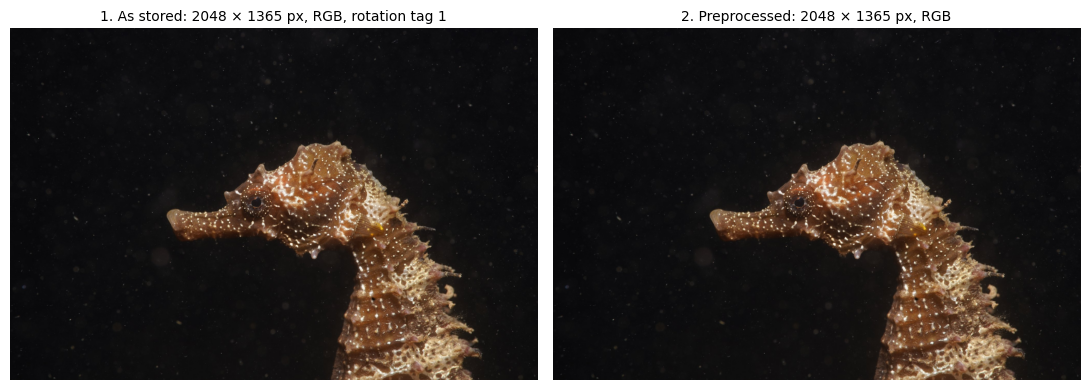

In [13]:
import matplotlib.pyplot as plt
from PIL import Image, ImageOps


def load_photograph(path):
    """One photograph as RGB, with the camera's rotation tag applied to the pixels."""
    with Image.open(path) as raw:
        image = ImageOps.exif_transpose(raw).convert("RGB")
        image.load()
    return image

def show(axis, image, title):
    """One image on an axis, with a title and no ticks."""
    axis.imshow(image)
    axis.set_title(title, fontsize=10)
    axis.set_axis_off()
    
with Image.open(example) as raw:
    rotation_tag = raw.getexif().get(0x0112, 1)  # EXIF Orientation; 1 means "no rotation"
    stored = raw.copy()
photograph = load_photograph(example)

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
show(axes[0], stored, f"1. As stored: {stored.width} × {stored.height} px, "
                      f"{stored.mode}, rotation tag {rotation_tag}")
show(axes[1], photograph, f"2. Preprocessed: {photograph.width} × {photograph.height} px, RGB")
plt.tight_layout()
plt.show()

### Step 3: the image that SAM 3 reads

The SAM 3 processor resizes the photograph to 1008 × 1008 px and normalizes the pixel values. The
resize does not keep the aspect ratio, so the seahorse can look stretched. The model never reads
the full resolution. The post-processing maps the boxes and masks back to the pixels of the
photograph, and the crops come from those pixels.

In [ ]:
## Loading SAM 3 
import torch
from transformers import Sam3Model, Sam3Processor  # needs transformers>=5.0

assert torch.cuda.is_available(), "This notebook needs a GPU."
DEVICE = "cuda"
# SAM 3 is gated on Hugging Face, so the notebook reads a local copy and never downloads it.
SAM3 = ROOT / Path(CONFIG["cache_dir"]).expanduser() / "models" / "sam3"
assert SAM3.exists(), (f"No SAM 3 model in {SAM3}. Accept the licence of facebook/sam3 on Hugging "
                       f"Face, log in with `hf auth login`, then run: "
                       f"hf download facebook/sam3 --local-dir '{SAM3}'")

processor = Sam3Processor.from_pretrained(SAM3)
model = Sam3Model.from_pretrained(SAM3).to(DEVICE).eval()  # inference mode

In [15]:
PROMPT = "seahorse"  # the open-vocabulary text prompt


@torch.no_grad()
def detect(processor, model, image, device):
    """One SAM 3 forward pass on a photograph: (inputs, raw outputs)."""
    inputs = processor(images=image, text=PROMPT, return_tensors="pt").to(device)
    return inputs, model(**inputs)


inputs, outputs = detect(processor, model, photograph, DEVICE)
# Undo the normalization to show the pixels as an image.
mean = torch.tensor(processor.image_processor.image_mean)[:, None, None]
std = torch.tensor(processor.image_processor.image_std)[:, None, None]
model_input = (inputs["pixel_values"][0].float().cpu() * std + mean).clamp(0, 1)
model_input = model_input.permute(1, 2, 0).numpy()

figure, axis = plt.subplots(figsize=(5, 5))
show(axis, model_input, f"3. SAM 3 input: {model_input.shape[1]} × {model_input.shape[0]} px")
plt.show()

OutOfMemoryError: CUDA out of memory. Tried to allocate 94.00 MiB. GPU 0 has a total capacity of 3.63 GiB of which 70.06 MiB is free. Including non-PyTorch memory, this process has 3.53 GiB memory in use. Of the allocated memory 3.32 GiB is allocated by PyTorch, and 131.84 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

### Step 4: detections

SAM 3 returns candidates for the prompt "seahorse". Each candidate has a box, a mask and a
confidence score. The figure shows every candidate with a score of at least `SHOW_THRESHOLD`.
Only the candidates at or above `BOX_THRESHOLD` become crops: they have a solid box and a blue
mask. A dashed grey box marks a rejected candidate.

In [ ]:
import numpy as np
from matplotlib.patches import Rectangle

MASK_THRESHOLD = 0.6  # probability at which a mask pixel counts as foreground




BOX_THRESHOLD = 0.7   # detection confidence; only the candidates at or above it give crops
SHOW_THRESHOLD = 0.1  # below BOX_THRESHOLD, to show the rejected candidates too
candidates = processor.post_process_instance_segmentation(
        outputs, threshold=SHOW_THRESHOLD, mask_threshold=MASK_THRESHOLD,
        target_sizes=inputs["original_sizes"].tolist())[0]
pixels = np.asarray(photograph)

overlay = pixels.astype(float)
blue = np.array([0, 114, 178])  # the masks of the kept detections
for score, mask in zip(candidates["scores"], candidates["masks"]):
    if score >= BOX_THRESHOLD:
        inside = np.asarray(mask.cpu(), dtype=bool)
        overlay[inside] = 0.55 * overlay[inside] + 0.45 * blue

figure, axis = plt.subplots(figsize=(8, 6))
show(axis, overlay.astype(np.uint8), f"4. Detections: kept if score ≥ {BOX_THRESHOLD}")
for box, score in zip(candidates["boxes"].tolist(), candidates["scores"].tolist()):
    kept = score >= BOX_THRESHOLD
    x1, y1, x2, y2 = box
    color = "#D55E00" if kept else "#BBBBBB"
    axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color,
                             linewidth=2, linestyle="-" if kept else "--"))
    axis.text(x1, y1, f"{score:.2f} {'kept' if kept else 'rejected'}", color="white",
              fontsize=9, va="bottom", bbox={"facecolor": color, "edgecolor": "none", "pad": 1.5})
plt.show()
print(f"{len(candidates['scores'])} candidates score at least {SHOW_THRESHOLD}; "
      f"{(candidates['scores'] >= BOX_THRESHOLD).sum()} are kept.")

### Steps 5 and 6: cropping and segmenting

Each kept detection gives one crop. `segmented_crop` grows the box by 5% of its size, crops the
photograph to it, and paints every pixel outside the mask white. The middle panel shows the mask
inside the crop. The right panel is the image that the full run writes as a PNG. The JPEG copy is
the same image with a longest edge of at most 2048 px.

In [ ]:
BOX_PADDING = 0.05  # the box grows by 5% of its own size before cropping


def segmented_crop(photograph, mask, box):
    """Crop to the box grown by BOX_PADDING, and paint every pixel outside the mask white.

    The margin matters: SAM 3 predicts the box and the mask apart, and the mask often spills
    past the box.
    """
    height, width = photograph.shape[:2]
    x1, y1, x2, y2 = (int(value) for value in box)
    pad_x, pad_y = int((x2 - x1) * BOX_PADDING), int((y2 - y1) * BOX_PADDING)
    x1, y1 = max(0, x1 - pad_x), max(0, y1 - pad_y)
    x2, y2 = min(width, x2 + pad_x), min(height, y2 + pad_y)
    pixels = photograph[y1:y2, x1:x2]
    return Image.fromarray(np.where(mask[y1:y2, x1:x2, None], pixels, 255))  # uint8, as pixels


found = processor.post_process_instance_segmentation(
        outputs, threshold=BOX_THRESHOLD, mask_threshold=MASK_THRESHOLD,
        target_sizes=inputs["original_sizes"].tolist())[0]  # the same call as the loop
for index, (box, score, mask) in enumerate(zip(found["boxes"], found["scores"], found["masks"])):
    mask, box = np.asarray(mask.cpu(), dtype=bool), box.tolist()
    # An all-true mask crops without painting; black pixels show the mask itself.
    cropped = segmented_crop(pixels, np.ones_like(mask), box)
    mask_view = segmented_crop(np.zeros_like(pixels), mask, box)
    segmented = segmented_crop(pixels, mask, box)

    figure, axes = plt.subplots(1, 3, figsize=(12, 4.5))
    show(axes[0], cropped, f"5. Cropped: {cropped.width} × {cropped.height} px")
    show(axes[1], mask_view, "Mask inside the crop")
    show(axes[2], segmented, "6. Segmented")
    figure.suptitle(f"{example.stem}_det{index}_cropped, score {score:.2f}")
    plt.tight_layout()
    plt.show()
    print(f"_det{index}: {segmented.width} × {segmented.height} px at full resolution")
if not len(found["scores"]):
    print(f"No detection scores at least {BOX_THRESHOLD}: this photograph gives no crop.")

## Segmenting

A photograph whose first crop is on disk is skipped, so an interrupted run resumes. The records of
earlier runs stay in `detections.json`.

In [ ]:
import json

from tqdm.auto import tqdm

COMPRESSED_MAX_EDGE = 2048  # longest edge of the JPEG copy that DINOv3 and BioCLIP read
JPEG_QUALITY = 85


# Relative paths in config.toml start at the folder that holds it.
OUTPUT = ROOT / Path(CONFIG["data_root"]).expanduser()
OVERWRITE = False  # True segments again the photographs that already have a crop

detections_file = OUTPUT / "detections.json"
detections = {}
if detections_file.exists():
    detections = {record["name"]: record for record in json.loads(detections_file.read_text())}
recorded = set(detections)
(OUTPUT / "segmented").mkdir(parents=True, exist_ok=True)
(OUTPUT / "segmented_compressed").mkdir(parents=True, exist_ok=True)
for path in tqdm(photographs, desc="SAM 3"):
    stem = path.stem
    # Keyed on _det0, because a photograph with no detection writes nothing.
    if not OVERWRITE and (OUTPUT / "segmented_compressed" / f"{stem}_det0_cropped.jpg").exists():
        continue
    image = load_photograph(path)
    inputs, outputs = detect(processor, model, image, DEVICE)
    found = processor.post_process_instance_segmentation(
        outputs, threshold=BOX_THRESHOLD, mask_threshold=MASK_THRESHOLD,
        target_sizes=inputs["original_sizes"].tolist())[0]
    pixels = np.asarray(image)
    for index, (box, score, mask) in enumerate(zip(found["boxes"], found["scores"], found["masks"])):
        name = f"{stem}_det{index}_cropped"
        crop = segmented_crop(pixels, np.asarray(mask.cpu(), dtype=bool), box.tolist())
        # Write the crop twice: a full-resolution PNG for MiewID, which reads fine details, and a
        # JPEG with a 2048 px longest edge for DINOv3 and BioCLIP, which resize to 224 px anyway.
        crop.save(OUTPUT / "segmented" / f"{name}.png")
        scale = COMPRESSED_MAX_EDGE / max(crop.size)
        small = crop if scale >= 1.0 else crop.resize(
            (int(crop.width * scale), int(crop.height * scale)), Image.LANCZOS)
        small.save(OUTPUT / "segmented_compressed" / f"{name}.jpg", quality=JPEG_QUALITY)
        detections[f"{name}.jpg"] = {"name": f"{name}.jpg", "photograph": str(path.relative_to(PHOTOGRAPHS)),
                                     "box": box.tolist(), "score": float(score)}

# Written only when this run made crops, so a run that skips everything leaves the file alone.
if detections.keys() != recorded:
    detections_file.write_text(json.dumps(list(detections.values()), indent=1))
print(f"{len(detections) - len(recorded)} new crops; {len(detections)} recorded in {detections_file}")